# Ideal solution phase diagram

The simplest binary system in landau: a solid and a liquid ideal solution. A few lines give the full phase diagram.

The second figure is a cut through it at `T_CUT`, showing the semigrand potential $\phi(\Delta\mu)$ of both phases. The phase with the lowest $\phi$ is stable, and the two curves cross at the transition. The dashed line in the phase diagram marks this cut.

Saves `Ideal_Solution.svg`/`.png` and `Ideal_Solution_1D.svg`/`.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import landau as ld
from landau import IdealSolution, LinePhase, plot_phase_diagram
from landau.calculate import calc_phase_diagram
from landau.phases import kB

In [2]:
OUT = "Ideal_Solution.svg"
OUT_1D = "Ideal_Solution_1D.svg"

T_CUT = 1000  # K, temperature of the 1D cut
MU_RANGE = (-1.25, -0.85)  # eV, chemical potential range of the 1D cut

FIGSIZE = (6.4, 4.8)
AXES = (1.1 / 6.4, 0.7 / 4.8, 5 / 6.4, 3.95 / 4.8)  # left, bottom, width, height: the same plot area in all figures
FONTSIZE = 13
DPI = 200

## Phases

Each ideal solution mixes two line phases: the pure A and pure B end members.

In [3]:
solid = IdealSolution("solid",
    LinePhase("A",    fixed_concentration=0, line_energy=-2.0, line_entropy=1.0 * kB),
    LinePhase("B",    fixed_concentration=1, line_energy=-3.0, line_entropy=1.5 * kB))
liquid = IdealSolution("liquid",
    LinePhase("A(l)", fixed_concentration=0, line_energy=-1.9, line_entropy=2.5 * kB),
    LinePhase("B(l)", fixed_concentration=1, line_energy=-2.9, line_entropy=2.2 * kB))

## Calculate

The full $T$–$c$ diagram, a $\Delta\mu$ scan at `T_CUT` that also keeps the unstable branches, and the two compositions that coexist at `T_CUT`.

In [4]:
df = calc_phase_diagram([solid, liquid], Ts=np.linspace(400, 1800, 100), mu=100)
df_cut = calc_phase_diagram([solid, liquid], Ts=[T_CUT], mu=np.linspace(*MU_RANGE, 200), keep_unstable=True)
coexist = calc_phase_diagram([solid, liquid], Ts=[T_CUT], mu=100).query("locus == 'boundary'")
coexist[["phase", "mu", "c"]]

,phase,mu,c
200,liquid,-1.035211,0.329906
201,solid,-1.035211,0.522831


## Phase diagram

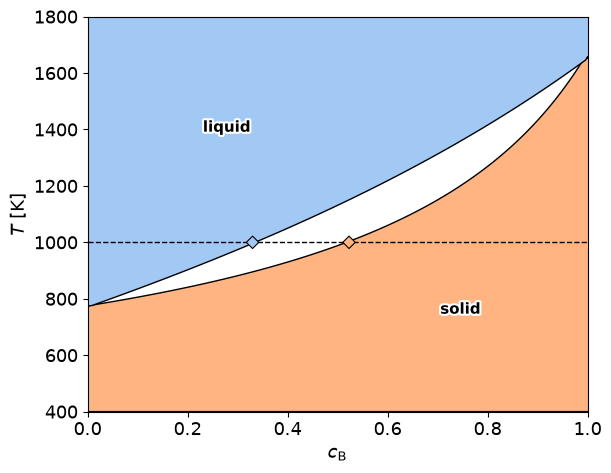

In [5]:
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig = plt.figure(figsize=FIGSIZE)
ax = fig.add_axes(AXES)

plot_phase_diagram(df, element="B", ax=ax)

# isotherm of the 1D cut, coexisting compositions marked
ax.axhline(T_CUT, color="k", ls="--", lw=1, zorder=5)
colors = ld.plot.get_phase_colors(df.phase.unique())
ax.scatter(coexist.c, [T_CUT] * len(coexist), color=[colors[p] for p in coexist.phase],
           marker="D", s=40, edgecolor="k", lw=0.8, zorder=10)

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)

## 1D cut at `T_CUT`

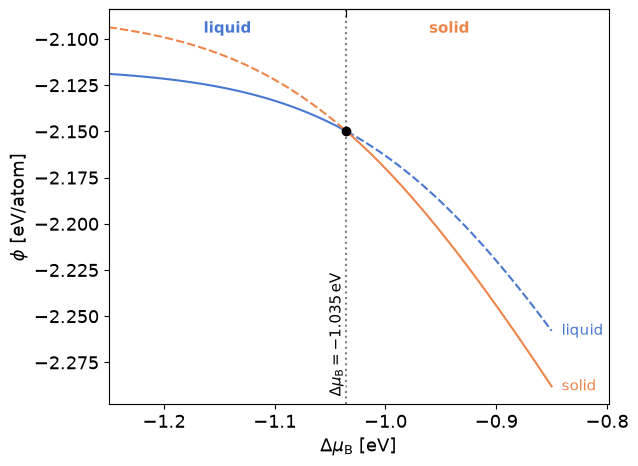

In [6]:
fig = plt.figure(figsize=FIGSIZE)
ax = fig.add_axes(AXES)
ld.plot.plot_1d_mu_phase_diagram(df_cut, element="B", ax=ax)
ax.set_xlabel(r"$\Delta\mu_\mathrm{B}$ [eV]")
ax.set_ylabel(r"$\phi$ [eV/atom]")

fig.savefig(OUT_1D)
fig.savefig(OUT_1D.replace(".svg", ".png"), dpi=DPI, transparent=True)